# 02 — The K-Means study (Session 11 core)

**Plan for this notebook:** (1) watch raw units corrupt the geometry, (2) fix it with
standardization, (3) choose k with the elbow and the silhouette like Session 11 taught,
(4) interpret the chosen clustering by its centroids.

Everything runs through `src/study.py` so imputation and scaling stay inside sklearn
pipelines — leakage-free by construction — and through 3 fixed seeds.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_elements
from study import build_feature_matrix, elbow_silhouette, fit_labels, raw_share_demo

df = load_elements()
X, feats = build_feature_matrix(df)   # spec approach B: 6 physical features, standardized
print(f"X: {X.shape} with features {feats}")

X: (118, 6) with features ['atomic_weight', 'density', 'atomic_radius', 'atomic_radius_rahm', 'en_pauling', 'electron_affinity']


## 1. Raw units: the failure exhibit (why Lab 2 matters)

Share of total pairwise squared distance each feature would own if we clustered **raw values**:

atomic_weight         78.71
atomic_radius         12.01
atomic_radius_rahm     8.51
density                0.72
electron_affinity      0.05
en_pauling             0.00


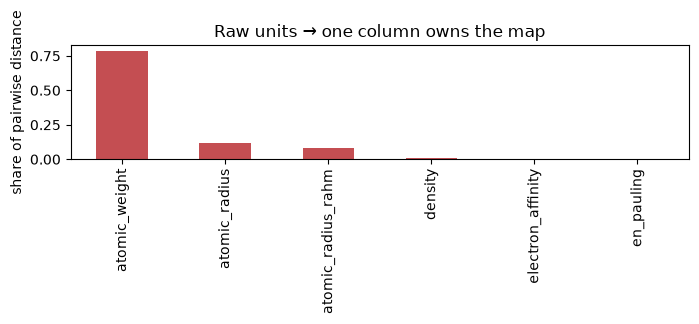

In [2]:
shares = pd.Series(raw_share_demo(df)).sort_values(ascending=False)
print((shares * 100).round(2).rename("raw-unit share of geometry (%)").to_string())
ax = shares.plot.bar(figsize=(7, 3.2), color="#C44E52")
ax.set_ylabel("share of pairwise distance"); ax.set_title("Raw units → one column owns the map")
plt.tight_layout(); plt.show()
plt.show()
import pathlib; pathlib.Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig = ax.figure
fig.savefig("reports/figures/f02_raw_share.png", dpi=150, bbox_inches="tight")
plt.show()


**Read this:** `atomic_weight` alone carries ~79% of the raw-unit geometry — clustering raw
values is silently a *weight-only* clustering. Density and chemistry barely matter. That is
an arbitrary dataset artifact, not chemistry. Standardization (next) makes every feature a
unitless standard deviation — the fair arena K-Means deserves.

## 2. Choosing k: elbow + silhouette (Session 11's two instruments)

3 seeds × k = 2…12. Both metrics computed on the same standardized geometry.

In [3]:
tab = elbow_silhouette(X)
print(tab.round(3).to_string())

k_star = int(tab.sil_mean.idxmax())
print(f"\nSilhouette picks k* = {k_star} (mean silhouette {tab.sil_mean.max():.3f})")

    inertia_mean  inertia_std  sil_mean  sil_std
k                                               
2        493.368        0.000     0.319    0.000
3        385.142        0.000     0.324    0.000
4        281.566        0.061     0.343    0.001
5        212.178        0.000     0.359    0.000
6        176.576        0.000     0.352    0.000
7        158.246        0.599     0.347    0.005
8        145.036        0.414     0.340    0.006
9        133.915        0.722     0.315    0.013
10       121.335        0.571     0.317    0.004
11       111.113        1.696     0.318    0.018
12       100.460        1.036     0.311    0.017

Silhouette picks k* = 5 (mean silhouette 0.359)


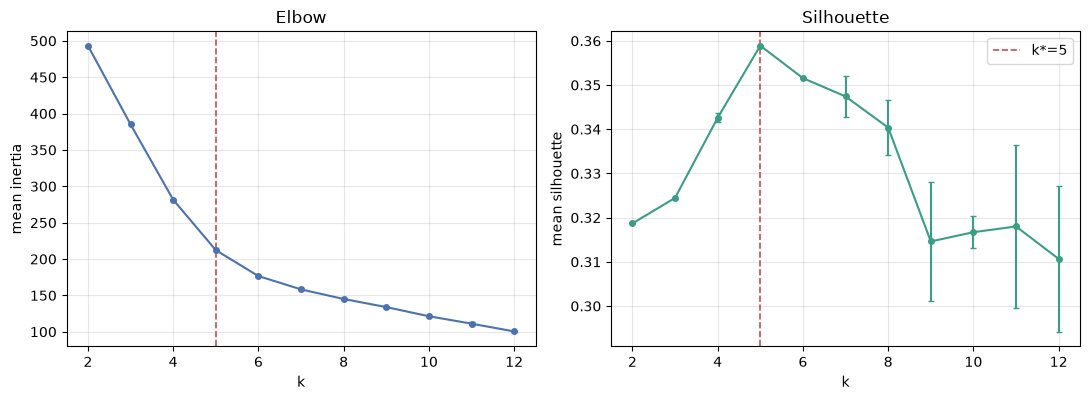

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.1))
a1.errorbar(tab.index, tab.inertia_mean, yerr=tab.inertia_std, marker="o", ms=4, color="#4C72B0", capsize=2)
a1.axvline(k_star, color="#C44E52", ls="--", lw=1.2)
a1.set_xlabel("k"); a1.set_ylabel("mean inertia"); a1.set_title("Elbow"); a1.grid(alpha=0.3)
a2.errorbar(tab.index, tab.sil_mean, yerr=tab.sil_std, marker="o", ms=4, color="#3A9E87", capsize=2)
a2.axvline(k_star, color="#C44E52", ls="--", lw=1.2, label=f"k*={k_star}")
a2.set_xlabel("k"); a2.set_ylabel("mean silhouette"); a2.set_title("Silhouette"); a2.grid(alpha=0.3); a2.legend()
plt.tight_layout(); plt.show()

plt.show()
import pathlib; pathlib.Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/f03_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. The chosen clustering and its centroids

Fitting at k\*: cluster sizes first, then each centroid in **standardized space** — a value
above 0 means *above the periodic table average* for that physical feature.

0    42
1    36
2     2
3     9
4    29
inertia = 212.18


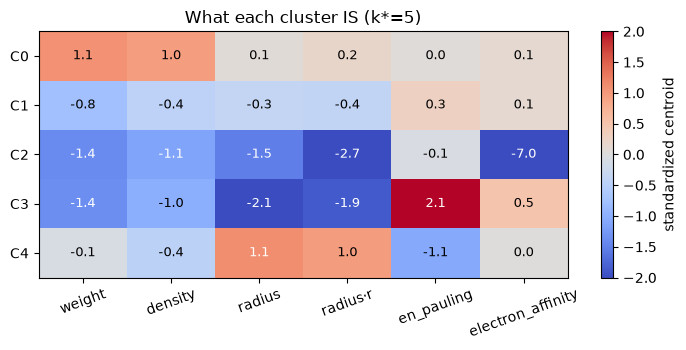

    atomic_weight  density  atomic_radius  atomic_radius_rahm  en_pauling  electron_affinity
C0           1.08     0.95           0.06                0.19        0.03               0.12
C1          -0.76    -0.43          -0.34               -0.38        0.29               0.12
C2          -1.39    -1.14          -1.53               -2.67       -0.07              -6.96
C3          -1.37    -1.01          -2.13               -1.87        2.14               0.49
C4          -0.09    -0.45           1.11                0.97       -1.07               0.01


In [5]:
labels, centroids, inertia = fit_labels(X, k=k_star, seed=0)
sizes = pd.Series(labels).value_counts().sort_index().rename("elements")
print(sizes.to_string()); print(f"inertia = {inertia:.2f}")

cent = pd.DataFrame(centroids, columns=feats, index=[f"C{i}" for i in range(k_star)])
fig, ax = plt.subplots(figsize=(7.2, 3.6))
im = ax.imshow(cent.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(feats)), [f.replace("atomic_", "").replace("_rahm", "·r") for f in feats], rotation=20)
ax.set_yticks(range(k_star), cent.index)
for i in range(k_star):
    for j in range(len(feats)):
        ax.text(j, i, f"{cent.values[i, j]:.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(cent.values[i, j]) > 1.1 else "black")
fig.colorbar(im, label="standardized centroid")
ax.set_title(f"What each cluster IS (k*={k_star})")
plt.tight_layout(); plt.show(); print(cent.round(2).to_string())
import pathlib; pathlib.Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/f04_centroids.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
viz = pd.DataFrame({"cluster": labels, "symbol": df.symbol.values,
                    "group_id": df.group_id.values, "weight": df.atomic_weight.values})
for i in range(k_star):
    members = viz[viz.cluster == i].sort_values("weight")
    print(f"C{i} ({len(members):>3}): " + " ".join(members.symbol.head(18).tolist()) +
          (" …" if len(members) > 18 else ""))

C0 ( 42): Hf Ta W Re Os Ir Pt Au Hg Tl Pb Bi Po At Pa Np U Am …
C1 ( 36): Li Be Ne Mg Al Si P Ti V Cr Mn Fe Ni Co Cu Zn Ga Ge …
C2 (  2): He Ar
C3 (  9): H B C N O F S Cl Br
C4 ( 29): Na K Ca Sc Rb Sr Y Zr Cs Ba La Ce Pr Nd Pm Sm Eu Gd …


## Reading the clusters (preview — full validation in notebook 03)

Look at the member lists: the light-metal cluster, the heavy transition blob, the dense
noble/interior cluster… chemistry is *visible* in unsupervised partitions — but "visible to
us" is not evidence. Notebook 03 quantifies the overlap with the actual periodic families
(ARI) and explains why some clusters blur (radii and density don't respect human group
carts, and the f-block elements have no `group_id` to grade against).

→ next: `03_validation_report.ipynb`